# Train on Jan 2023 - Apr 2024, validate and test on May - Jul 2024

**What this notebook does**
1. Reads the **2023 parquet** (10 airports, weather already merged), the **2024 all-airports parquet** and the **2024 weather file**.
2. Builds the 2024 flight table (flights between the 10 airports) and **merges it with the 2024 weather** in exactly the same way as 2023 (latest weather observation at least 2 hours before scheduled departure).
3. Joins 2023 + 2024 into one continuous timeline, builds the features, and splits **by date**:

| part | period |
|---|---|
| train | Jan 2023 - Apr 2024 (the first 30 days are only used as history) |
| validation | May 2024 (used to tune the models and to pick the threshold) |
| test | Jun - Jul 2024 (used once, at the end) |

You can change the months in the settings cell (`VAL_MONTHS`, `TEST_MONTHS`).
4. Trains logistic regression, random forest and gradient boosting (plus a simple average), and prints precision, recall, F1, PR-AUC, ROC-AUC, confusion counts, scores for each test month, a bootstrap test, an ablation table and feature importance.

**Question answered:** will a scheduled flight depart **15+ minutes late**, using only what is known **2 hours before** scheduled departure?

**Input files** (kept in a Google Drive folder, so no upload is needed after the first time): `flights_weather_2023.parquet`, `flights_2024_all_airports.parquet`, `weather_2024_all.csv`.

**What is not included, and why:** the 2024 file has no `TAIL_NUM` or `ARR_DELAY` (and the 2023 parquet has none either), so the aircraft-rotation features cannot be built. The airport-status features use only the flights among your 10 airports, in both years, so that training and test see the same kind of data.

In [1]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve, roc_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

# ------------------------------ settings ------------------------------
TRAIN_END      = "2024-04-30"      # last day of the training period (training starts with the first 2023 flight)
VAL_MONTHS     = [5]               # validation months of 2024
TEST_MONTHS    = [6, 7]            # test months of 2024
LEAD_MIN       = 120               # prediction time = this many minutes before scheduled departure (= weather lag)
WEATHER_LAG_H  = 2                 # weather observed at least this long before departure
MAX_WX_AGE_H   = 3                 # ...and not older than this (beyond the lag)
FFILL_HOURS    = 3                 # fill a missing temp / wind / visibility from a reading at most this old
WX_LIKE_2023   = True              # 2024 file has 5-minute rows; keep only rows with a temperature (hourly METAR/SPECI), like the 2023 file
WARMUP_DAYS    = 30
RANDOM_STATE   = 42
QUICK_TEST     = False             # True = tiny, fast run to check that everything works (scores are NOT meaningful)

LR_C_GRID      = [0.01, 0.1, 1, 10]
RF_SEARCH_ITER = 6
RF_SEARCH_ROWS = 150_000
N_TREES_SEARCH = 100
N_TREES_FINAL  = 200
HGB_CONFIGS    = [dict(learning_rate=0.1,  max_leaf_nodes=31, min_samples_leaf=100),
                  dict(learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=200),
                  dict(learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=300),
                  dict(learning_rate=0.1,  max_leaf_nodes=15, min_samples_leaf=50)]
HGB_MAX_ITER   = 250
RUN_ABLATION   = True
N_BOOT         = 200
if QUICK_TEST:
    RF_SEARCH_ITER, RF_SEARCH_ROWS, N_TREES_SEARCH, N_TREES_FINAL = 2, 40_000, 20, 30
    HGB_CONFIGS, HGB_MAX_ITER, N_BOOT, LR_C_GRID = HGB_CONFIGS[:1], 60, 30, [1]

AIRPORT_TZ = {"ATL": "America/New_York", "CLT": "America/New_York", "MCO": "America/New_York",
              "ORD": "America/Chicago", "DFW": "America/Chicago", "DEN": "America/Denver",
              "PHX": "America/Phoenix", "LAS": "America/Los_Angeles", "LAX": "America/Los_Angeles",
              "SEA": "America/Los_Angeles"}
AIRPORTS = sorted(AIRPORT_TZ)
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## 1. Load the three files (from Google Drive, so you only upload once)

Put the three files in one Google Drive folder (default: `MyDrive/flight_delay_inputs`). The notebook mounts Drive and reads them from there. If a file is missing, it asks you to upload it and then **saves a copy to that Drive folder**, so the next session needs no upload. Change `DRIVE_DIR` if your files are in another folder.

In [2]:
DRIVE_DIR = Path("/content/drive/MyDrive/flight_delay_inputs")
PATTERNS = {"flights_2023": "*flights_weather_2023*.parquet",
            "flights_2024": "*flights_2024_all_airports*.parquet",
            "weather_2024": "*weather_2024*.csv"}
def find_files(folder):
    out = {}
    if folder.exists():
        for k, pat in PATTERNS.items():
            hits = sorted(folder.glob(pat))
            if hits:
                out[k] = hits[-1]
    return out

try:
    from google.colab import drive, files
    drive.mount("/content/drive")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

found = {**find_files(Path(".")), **(find_files(DRIVE_DIR) if IN_COLAB else {})}       # Drive copy wins
if len(found) < 3 and IN_COLAB:
    print("Not found in", DRIVE_DIR, ":", [k for k in PATTERNS if k not in found], "- upload them now (select together); they are saved to Drive for next time ...")
    for name, data in files.upload().items():
        (DRIVE_DIR / name).write_bytes(data)
    found = {**find_files(Path(".")), **find_files(DRIVE_DIR)}
missing = [k for k in PATTERNS if k not in found]
if missing:
    raise FileNotFoundError(f"Could not find: {missing}. Expected names like {list(PATTERNS.values())} in {DRIVE_DIR}")
for k, v in found.items():
    print(f"{k:13s} {v}  ({v.stat().st_size/1e6:.1f} MB)")

Mounted at /content/drive
flights_2023  /content/drive/MyDrive/flight_delay_inputs/flights_weather_2023.parquet  (14.5 MB)
flights_2024  /content/drive/MyDrive/flight_delay_inputs/flights_2024_all_airports.parquet  (57.1 MB)
weather_2024  /content/drive/MyDrive/flight_delay_inputs/weather_2024_all.csv  (65.7 MB)


## 2. 2023 flights (already merged with weather)

In [3]:
d23 = pd.read_parquet(found["flights_2023"])
d23["flight_date"] = d23["flight_date"].astype("datetime64[ns]")
d23["year"] = 2023
print("2023:", d23.shape, "|", d23["flight_date"].min().date(), "to", d23["flight_date"].max().date())
print("delay rate by month:", (d23.groupby("month")["dep_del15"].mean() * 100).round(1).to_dict())
route_distance = d23.drop_duplicates("route").set_index("route")["distance_mi"]     # distance is fixed per route

2023: (474503, 41) | 2023-01-01 to 2023-12-31
delay rate by month: {1: 23.6, 2: 22.3, 3: 25.7, 4: 26.0, 5: 24.2, 6: 31.3, 7: 33.6, 8: 26.5, 9: 19.9, 10: 18.0, 11: 15.0, 12: 17.1}


## 3. Build the 2024 flight table

The 2024 file holds every US flight, with the columns needed for modelling. We keep flights where **both** origin and destination are among the 10 airports, drop cancelled / diverted flights and flights without a departure delay, and add the same columns as in 2023.
`distance_mi` is not in the 2024 file, so it is taken from the 2023 data (the distance of a route never changes).

In [4]:
a = pd.read_parquet(found["flights_2024"])
a["flight_date"] = a["flight_date"].astype("datetime64[ns]")
log = {"2024 rows in file (all airports)": len(a)}
a = a[a["origin"].isin(AIRPORTS) & a["dest"].isin(AIRPORTS)]
log["flights between the 10 airports"] = len(a)
a = a[~(a["cancelled"] | a["diverted"])]
log["  after removing cancelled / diverted"] = len(a)
a = a[a["dep_delay_min"].notna()]
log["  after removing rows without departure delay"] = len(a)

hh, mm = a["crs_dep_time"] // 100, a["crs_dep_time"] % 100
a["sched_dep_local"] = (a["flight_date"] + pd.to_timedelta(hh, unit="h") + pd.to_timedelta(mm, unit="m")).astype("datetime64[ns]")

def local_to_utc(local, airport):
    pieces = []
    for ap, tz in AIRPORT_TZ.items():
        m = airport == ap
        if m.any():
            loc = local[m].dt.tz_localize(tz, ambiguous=np.ones(int(m.sum()), dtype=bool), nonexistent="shift_forward")
            pieces.append(loc.dt.tz_convert("UTC").dt.tz_localize(None))
    return pd.concat(pieces).reindex(local.index).astype("datetime64[ns]")

for c in ["airline", "origin", "dest"]:
    a[c] = a[c].astype(str)
a["sched_dep_utc"] = local_to_utc(a["sched_dep_local"], a["origin"])
assert a["sched_dep_utc"].notna().all()
a["route"] = a["origin"] + "-" + a["dest"]
a["day_of_week"] = a["flight_date"].dt.dayofweek + 1               # 1 = Monday, same as 2023
a["sched_dep_hour"] = a["sched_dep_local"].dt.hour.astype("int64")
a["distance_mi"] = a["route"].map(route_distance)
log["  routes without a 2023 distance (left empty)"] = int(a["distance_mi"].isna().sum())
a["dep_del15"] = (a["dep_delay_min"] >= 15).astype("int64")
a["month"] = a["flight_date"].dt.month.astype("int64"); a["year"] = 2024
a = a.sort_values(["flight_date", "sched_dep_utc", "origin", "dest", "flight_number"]).reset_index(drop=True)
for k, v in log.items():
    print(f"{k:<55}{v:>12,}")
print("\n2024 delay rate by month:", (a.groupby("month")["dep_del15"].mean() * 100).round(1).to_dict())

2024 rows in file (all airports)                          7,079,080
flights between the 10 airports                             483,916
  after removing cancelled / diverted                       483,916
  after removing rows without departure delay               478,099
  routes without a 2023 distance (left empty)                     0

2024 delay rate by month: {1: 24.4, 2: 16.8, 3: 24.1, 4: 21.6, 5: 30.4, 6: 29.3, 7: 34.1, 8: 26.2, 9: 17.6, 10: 15.5, 11: 15.7, 12: 20.3}


## 4. Clean the 2024 weather and merge it with the 2024 flights

The cleaning follows the 2023 weather steps. Differences in this file that are handled here:
- station names have a `K` prefix (`KATL`), the time has a time-zone suffix, and missing values are written `M`;
- the file has a row **every 5 minutes**, but temperature, precipitation and weather codes are only filled in hourly or for special reports. The 2023 file has only those hourly / special rows. To keep 2023 and 2024 comparable, only rows with a temperature are kept (`WX_LIKE_2023`). The per-station row counts printed below should be close to 2023 (about 9,000 - 11,000 per station).

In [5]:
wx = pd.read_csv(found["weather_2024"], dtype={"station": "string", "skyc1": "string", "wxcodes": "string"}, low_memory=False)
print("raw 2024 weather:", wx.shape)
wx["valid"] = pd.to_datetime(wx["valid"], utc=True, errors="coerce").dt.tz_localize(None)
st = wx["station"].str.strip().str.upper()
wx["station"] = st.where(~(st.str.len().eq(4) & st.str.startswith("K")), st.str[1:])
wx = wx.dropna(subset=["valid", "station"])
wx["station"] = wx["station"].astype(str)      # same text type as the flight origin column
miss_st = sorted(set(AIRPORTS) - set(wx["station"]))
if miss_st: print("WARNING: no weather for", miss_st)
wx = wx[wx["station"].isin(AIRPORTS)]
for c in ["tmpf", "sknt", "gust", "vsby", "p01i", "skyl1"]:
    wx[c] = pd.to_numeric(wx[c], errors="coerce")                       # 'M' -> NaN
wx["wxcodes"] = wx["wxcodes"].replace("M", pd.NA); wx["skyc1"] = wx["skyc1"].replace("M", pd.NA)
if WX_LIKE_2023:
    n_all = len(wx); wx = wx[wx["tmpf"].notna()]
    print(f"kept {len(wx):,} of {n_all:,} rows (rows with a temperature)")
print(wx.groupby("station").size().to_dict())

RANGES = {"tmpf": (-40, 130), "sknt": (0, 120), "gust": (0, 150), "vsby": (0, 20), "p01i": (0, 10), "skyl1": (0, 60000)}
for c, (lo, hi) in RANGES.items():
    out = (wx[c] < lo) | (wx[c] > hi)
    if out.any(): print(f"{c}: {int(out.sum())} impossible value(s) set to empty")
    wx.loc[out, c] = np.nan
wx["_n"] = wx.notna().sum(axis=1)
wx = wx.sort_values(["station", "valid", "_n"], ascending=[True, True, False]).drop_duplicates(["station", "valid"]).drop(columns="_n").reset_index(drop=True)

for c in ["tmpf", "sknt", "vsby"]:                                        # previous reading, at most FFILL_HOURS old
    last_seen = wx["valid"].where(wx[c].notna()).groupby(wx["station"]).ffill()
    filled = wx.groupby("station")[c].ffill()
    wx[c] = filled.where((wx["valid"] - last_seen) <= pd.Timedelta(hours=FFILL_HOURS))
wx["wx_has_gust"] = wx["gust"].notna().astype("int8"); wx["gust"] = wx["gust"].fillna(0)
wx["p01i"] = wx["p01i"].fillna(0)
wx["skyc1"] = wx["skyc1"].fillna("UNK").str.strip().str.upper()
wx["ceiling_ft"] = np.where(wx["skyc1"].isin(["BKN", "OVC", "VV"]), wx["skyl1"], 50000.0)
codes = wx["wxcodes"].fillna("").str.upper()
fl_ = lambda tok, rx=False: codes.str.contains(tok, regex=rx).astype("int8")
wx["wx_rain"], wx["wx_snow"], wx["wx_thunder"], wx["wx_fog"] = fl_("RA"), fl_("SN"), fl_("TS"), fl_("FG")
wx["wx_mist"], wx["wx_drizzle"], wx["wx_haze"], wx["wx_freezing"] = fl_("BR"), fl_("DZ"), fl_("HZ"), fl_("FZ")
wx["wx_ice_hail"], wx["wx_heavy"] = fl_(r"PL|GR|GS|IC|SG", True), fl_("+")
wx["wxcodes"] = wx["wxcodes"].fillna("")
wx = wx.rename(columns={"valid": "wx_obs_utc", "tmpf": "wx_temp_f", "sknt": "wx_wind_kt", "gust": "wx_gust_kt", "vsby": "wx_vis_mi",
                        "p01i": "wx_precip_1h_in", "skyc1": "wx_sky_cover", "ceiling_ft": "wx_ceiling_ft", "wxcodes": "wx_codes"}).drop(columns="skyl1")
wx["wx_obs_utc"] = wx["wx_obs_utc"].astype("datetime64[ns]")
wx = wx.sort_values("wx_obs_utc").reset_index(drop=True)
print("weather rows after cleaning:", len(wx), "| first / last:", wx["wx_obs_utc"].min(), "/", wx["wx_obs_utc"].max())
print("missing values:", wx.isna().sum()[lambda s: s > 0].to_dict())

raw 2024 weather: (1099404, 10)
kept 101,419 of 1,099,404 rows (rows with a temperature)
{'ATL': 10156, 'CLT': 10482, 'DEN': 10134, 'DFW': 10311, 'LAS': 9211, 'LAX': 10581, 'MCO': 9973, 'ORD': 10647, 'PHX': 9101, 'SEA': 10823}
vsby: 1 impossible value(s) set to empty
weather rows after cleaning: 101419 | first / last: 2024-01-01 00:00:00 / 2024-12-31 23:56:00
missing values: {}


In [6]:
a["wx_cutoff_utc"] = (a["sched_dep_utc"] - pd.Timedelta(hours=WEATHER_LAG_H)).astype("datetime64[ns]")
m24 = pd.merge_asof(a.sort_values("wx_cutoff_utc"), wx.sort_values("wx_obs_utc"), left_on="wx_cutoff_utc", right_on="wx_obs_utc",
                    left_by="origin", right_by="station", direction="backward", tolerance=pd.Timedelta(hours=MAX_WX_AGE_H))
m24 = m24.drop(columns="station")
m24["wx_age_min"] = ((m24["wx_cutoff_utc"] - m24["wx_obs_utc"]).dt.total_seconds() / 60).round(1)
ok = m24["wx_obs_utc"].notna()
assert (m24.loc[ok, "wx_obs_utc"] <= m24.loc[ok, "wx_cutoff_utc"]).all(), "weather leakage!"
assert len(m24) == len(a), "merge changed the number of flights"
m24 = m24.sort_values(["flight_date", "sched_dep_utc", "origin", "dest", "flight_number"]).reset_index(drop=True)
print(f"2024 flights with weather: {ok.sum():,} of {len(m24):,} ({ok.mean():.2%}); without weather: {(~ok).sum():,}")
print("weather age at cut-off (minutes), 2024:", m24["wx_age_min"].describe().round(1)[["mean", "50%", "max"]].to_dict())
print("weather age at cut-off (minutes), 2023:", d23["wx_age_min"].describe().round(1)[["mean", "50%", "max"]].to_dict())
if (~ok).any():
    print("no-weather flights by origin:", m24.loc[~ok, "origin"].value_counts().to_dict())

2024 flights with weather: 478,039 of 478,099 (99.99%); without weather: 60
weather age at cut-off (minutes), 2024: {'mean': 26.6, '50%': 24.0, 'max': 179.0}
weather age at cut-off (minutes), 2023: {'mean': 26.9, '50%': 26.0, 'max': 177.0}
no-weather flights by origin: {'LAS': 20, 'LAX': 15, 'SEA': 7, 'ATL': 5, 'DEN': 5, 'PHX': 5, 'ORD': 2, 'MCO': 1}


## 5. Put 2023 and 2024 on one timeline and split by date

Flights after the last test month are dropped: they are not needed, and nothing from them may be used. The history features (trailing delay rates) look only at earlier days, so the 2023 flights act as history for early 2024.

In [7]:
COMMON = [c for c in d23.columns if c in m24.columns and c != "split"]
df = pd.concat([d23[COMMON], m24[COMMON]], ignore_index=True)
df = df.drop(columns=[c for c in ["crs_elapsed_min"] if c in df.columns])
flag_cols = [c for c in df.columns if c.startswith("wx_") and c not in ("wx_codes", "wx_sky_cover", "wx_obs_utc", "wx_cutoff_utc")]
df[flag_cols] = df[flag_cols].astype("float64")
for c in ["airline", "origin", "dest", "route", "wx_sky_cover", "wx_codes"]:
    df[c] = df[c].astype(str)

val_ids  = set(VAL_MONTHS); test_ids = set(TEST_MONTHS)
last_test_day = pd.Timestamp(2024, max(test_ids), 1) + pd.offsets.MonthEnd(0)
n_all = len(df); df = df[df["flight_date"] <= last_test_day].reset_index(drop=True)
print(f"dropped {n_all - len(df):,} flights after {last_test_day.date()}")

is24 = df["year"] == 2024
df["split"] = "unused"
df.loc[df["flight_date"] <= pd.Timestamp(TRAIN_END), "split"] = "train"
df.loc[is24 & df["month"].isin(val_ids) & (df["flight_date"] > pd.Timestamp(TRAIN_END)), "split"] = "validation"
df.loc[is24 & df["month"].isin(test_ids) & (df["flight_date"] > pd.Timestamp(TRAIN_END)), "split"] = "test"
print("split counts:", df["split"].value_counts().to_dict())
gap = df[df["split"] == "unused"]
if len(gap):
    print(f"NOTE: {len(gap):,} flights between the training end and the validation/test months are not used (months {sorted(gap['month'].unique())})")
df = df.sort_values(["flight_date", "sched_dep_utc", "origin", "dest", "flight_number"]).reset_index(drop=True)

dropped 201,507 flights after 2024-07-31
split counts: {'train': 627214, 'test': 82039, 'validation': 41842}


## 6. Features

Every feature is known 2 hours before departure:
- schedule: airline, origin, destination, hour, weekday, distance, holiday window;
- weather at the last observation at least 2 hours before departure;
- **trailing delay rates** (route, route x hour, airline, origin, plus 7-day, previous-day, origin x hour, airline x origin), each computed only from **earlier days**;
- **airport status**: share of earlier flights from the same airport that were already 15+ min late in the 1, 3 and 6 hours that end 15 minutes before the prediction time, and how busy the airport is scheduled to be. Based on the flights among the 10 airports, in both years.

In [8]:
bad_wind = ((df["wx_gust_kt"] < df["wx_wind_kt"]) & (df["wx_has_gust"] == 1)) | ((df["wx_wind_kt"] >= 35) & (df["wx_has_gust"] == 0))
print("implausible wind readings set to empty:", int(bad_wind.sum()))
df.loc[bad_wind, "wx_wind_kt"] = np.nan

holidays = USFederalHolidayCalendar().holidays(start="2022-12-01", end="2025-01-31")
days = pd.date_range(df["flight_date"].min() - pd.Timedelta(days=10), df["flight_date"].max() + pd.Timedelta(days=10))
near = pd.Series(0, index=days)
for h in holidays:
    near.loc[h - pd.Timedelta(days=3): h + pd.Timedelta(days=3)] = 1
df["is_holiday_window"] = df["flight_date"].map(near).fillna(0).astype(int)

def add_trailing_rate(data, keys, name, window_days=30, min_n=20, target="dep_del15"):
    daily = (data.groupby(keys + ["flight_date"])[target].agg(n="size", k="sum").reset_index()
                 .sort_values("flight_date").set_index("flight_date"))
    roll = daily.groupby(keys)[["n", "k"]].rolling(f"{window_days}D", closed="left").sum().reset_index()   # previous days only
    roll[name] = np.where(roll["n"] >= min_n, roll["k"] / roll["n"], np.nan)
    return data.merge(roll[keys + ["flight_date", name]], on=keys + ["flight_date"], how="left")

n = len(df)
df["sched_dep_hour"] = df["sched_dep_hour"].astype(int)
df = add_trailing_rate(df, ["route"], "hist_route_rate", 30, 20)
df = add_trailing_rate(df, ["route", "sched_dep_hour"], "hist_route_hour_rate", 30, 5)
df = add_trailing_rate(df, ["airline"], "hist_airline_rate", 30, 50)
df = add_trailing_rate(df, ["origin"], "hist_origin_rate", 30, 50)
df = add_trailing_rate(df, ["origin"], "hist_origin_rate_7d", 7, 30)
df = add_trailing_rate(df, ["route"], "hist_route_rate_7d", 7, 10)
df = add_trailing_rate(df, ["origin"], "hist_origin_prevday_rate", 1, 20)
df = add_trailing_rate(df, ["origin", "sched_dep_hour"], "hist_origin_hour_rate", 30, 10)
df = add_trailing_rate(df, ["airline", "origin"], "hist_airline_origin_rate", 30, 30)
assert len(df) == n
df = df.sort_values(["flight_date", "sched_dep_utc", "origin", "dest", "flight_number"]).reset_index(drop=True)

implausible wind readings set to empty: 2


In [9]:
# ---- airport status (all in the local clock of the origin airport, minutes) ----
df["_t"] = df["sched_dep_local"].values.astype("datetime64[m]").astype("int64")
AIRPORT_FEATS = ["airport_late_rate_1h", "airport_late_rate_3h", "airport_late_rate_6h", "airport_n_3h",
                 "airport_mean_delay_3h", "airport_sched_load_60"]
for c in AIRPORT_FEATS:
    df[c] = np.nan

def window_stats(ts, cum_late, cum_delay, tq, width, min_n):
    lo = np.searchsorted(ts, tq - LEAD_MIN - width, side="right")        # flights with  C-width < sched <= C-15,  C = tq - LEAD_MIN
    hi = np.searchsorted(ts, tq - LEAD_MIN - 15, side="right")
    n = hi - lo; ok = n >= min_n
    rate = np.where(ok, (cum_late[hi] - cum_late[lo]) / np.maximum(n, 1), np.nan)
    mean_delay = np.where(ok, (cum_delay[hi] - cum_delay[lo]) / np.maximum(n, 1), np.nan)
    return rate, n, mean_delay

for o in AIRPORTS:
    sub = df[df["origin"] == o].sort_values("_t")
    ts = sub["_t"].values
    cum_late = np.concatenate([[0], np.cumsum((sub["dep_delay_min"].values >= 15).astype(float))])
    cum_delay = np.concatenate([[0], np.cumsum(np.clip(sub["dep_delay_min"].values, -15, 180))])
    m = (df["origin"] == o).values; tq = df.loc[m, "_t"].values
    r1, _, _ = window_stats(ts, cum_late, cum_delay, tq, 60, 3)
    r3, n3, md3 = window_stats(ts, cum_late, cum_delay, tq, 180, 5)
    r6, _, _ = window_stats(ts, cum_late, cum_delay, tq, 360, 10)
    load = np.searchsorted(ts, tq + 30, side="left") - np.searchsorted(ts, tq - 30, side="left")
    df.loc[m, "airport_late_rate_1h"], df.loc[m, "airport_late_rate_3h"], df.loc[m, "airport_late_rate_6h"] = r1, r3, r6
    df.loc[m, "airport_n_3h"], df.loc[m, "airport_mean_delay_3h"], df.loc[m, "airport_sched_load_60"] = n3, md3, load

# brute-force check on random flights: the fast code must equal a plain filter, and never use anything newer than C - 15 min
rng = np.random.RandomState(RANDOM_STATE)
for i in rng.choice(len(df), 150, replace=False):
    o, tq = df.at[i, "origin"], df.at[i, "_t"]
    s = df[(df["origin"] == o) & (df["_t"] > tq - LEAD_MIN - 180) & (df["_t"] <= tq - LEAD_MIN - 15)]
    expect = (s["dep_delay_min"] >= 15).mean() if len(s) >= 5 else np.nan
    got = df.at[i, "airport_late_rate_3h"]
    assert (np.isnan(expect) and np.isnan(got)) or abs(expect - got) < 1e-9, "airport-status check failed"
print("brute-force check passed on 150 random flights")

for c in ["sched_dep_hour", "day_of_week"]:
    df[c] = df[c].astype(str)
df["wx_sky_cover"] = df["wx_sky_cover"].fillna("UNK").astype(str)

WX_FLAGS = ["wx_has_gust", "wx_rain", "wx_snow", "wx_thunder", "wx_fog", "wx_mist", "wx_drizzle", "wx_haze", "wx_freezing", "wx_ice_hail", "wx_heavy"]
BASE_CAT = ["airline", "origin", "dest", "sched_dep_hour", "day_of_week", "wx_sky_cover"]
BASE_NUM = (["distance_mi", "is_holiday_window", "wx_temp_f", "wx_wind_kt", "wx_gust_kt", "wx_vis_mi", "wx_precip_1h_in", "wx_ceiling_ft"] + WX_FLAGS +
            ["hist_route_rate", "hist_route_hour_rate", "hist_airline_rate", "hist_origin_rate"])
HIST_EXTRA = ["hist_origin_rate_7d", "hist_route_rate_7d", "hist_origin_prevday_rate", "hist_origin_hour_rate", "hist_airline_origin_rate"]
FEATURE_SETS = {"A. base (weather, schedule, 30-day rates)": (BASE_CAT, BASE_NUM),
                "B. + extra trailing rates": (BASE_CAT, BASE_NUM + HIST_EXTRA),
                "C. + airport status (full)": (BASE_CAT, BASE_NUM + HIST_EXTRA + AIRPORT_FEATS)}
CAT, NUM = FEATURE_SETS["C. + airport status (full)"]; FEATURES = CAT + NUM
FORBIDDEN = {"dep_delay_min", "dep_del15", "split", "wx_obs_utc", "wx_cutoff_utc", "wx_age_min", "sched_dep_utc", "sched_dep_local",
             "flight_date", "month", "year", "_t", "arr_delay_min", "arr_del15"}
assert not (set(FEATURES) & FORBIDDEN), "a forbidden column is in the feature list"
print(len(FEATURES), "features")

brute-force check passed on 150 random flights
40 features


## 7. Chronological split

In [10]:
first_day = df["flight_date"].min() + pd.Timedelta(days=WARMUP_DAYS)
model_df = df[df["flight_date"] >= first_day]
print(f"dropped {len(df) - len(model_df):,} warm-up flights (before {first_day.date()})")
train = model_df[model_df["split"] == "train"].reset_index(drop=True)
val   = model_df[model_df["split"] == "validation"].reset_index(drop=True)
test  = model_df[model_df["split"] == "test"].reset_index(drop=True)
if QUICK_TEST:
    train = train.sample(150_000, random_state=RANDOM_STATE).sort_values("sched_dep_utc").reset_index(drop=True)
y_train, y_val, y_test = (d["dep_del15"].values for d in (train, val, test))
X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]
assert train["flight_date"].max() < val["flight_date"].min() <= val["flight_date"].max() < test["flight_date"].min(), "split is not chronological"
print(pd.DataFrame({"flights": [len(train), len(val), len(test)], "delay_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
                    "from": [d.flight_date.min().date() for d in (train, val, test)],
                    "to": [d.flight_date.max().date() for d in (train, val, test)]}, index=["train", "validation", "test"]).round(3))
print("\ndelay rate by month in training / validation / test:")
tab = model_df[model_df["split"] != "unused"].groupby(["year", "month", "split"])["dep_del15"].agg(["size", "mean"]).round(3)
print(tab.to_string())
print("\nmissing values in training features:"); print(X_train.isna().mean()[lambda s: s > 0].round(3).to_string())

dropped 36,122 warm-up flights (before 2023-01-31)
            flights  delay_rate        from          to
train        591092       0.232  2023-01-31  2024-04-30
validation    41842       0.304  2024-05-01  2024-05-31
test          82039       0.317  2024-06-01  2024-07-31

delay rate by month in training / validation / test:
                        size   mean
year month split                   
2023 1     train        1023  0.291
     2     train       34275  0.223
     3     train       39327  0.257
     4     train       38589  0.260
     5     train       40657  0.242
     6     train       39661  0.313
     7     train       40994  0.336
     8     train       41772  0.265
     9     train       40241  0.199
     10    train       42472  0.180
     11    train       39708  0.150
     12    train       39662  0.171
2024 1     train       36423  0.244
     2     train       35875  0.168
     3     train       40401  0.241
     4     train       40012  0.216
     5     validation  

## 8. Helper functions

In [11]:
def best_f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.argmax(f1[:-1])])

def metrics_at(y, s, thr):
    pred = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"threshold": round(float(thr), 4), "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0),
            "roc_auc": roc_auc_score(y, s), "pr_auc": average_precision_score(y, s),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def make_preprocessor(for_linear, cat, num):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if for_linear:
        steps.append(("scale", StandardScaler()))
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=for_linear, dtype=np.float32)
    return ColumnTransformer([("num", Pipeline(steps), num), ("cat", ohe, cat)], sparse_threshold=0.3 if for_linear else 0.0)

scores_val, scores_test = {}, {}

## 9. Baselines
1. **Majority class:** always predicts "not delayed".
2. **Historical rate:** score = trailing 30-day delay rate of the same route and hour (fallbacks: route rate, then training average); threshold chosen on validation.

In [12]:
def hist_score(d):
    return d["hist_route_hour_rate"].fillna(d["hist_route_rate"]).fillna(y_train.mean()).values
scores_val["Historical-rate baseline"], scores_test["Historical-rate baseline"] = hist_score(val), hist_score(test)
scores_val["Majority-class baseline"], scores_test["Majority-class baseline"] = np.zeros(len(val)), np.zeros(len(test))

## 10. Logistic regression

In [13]:
t0 = time.time()
prep_lr = make_preprocessor(True, CAT, NUM).fit(X_train)
Xtr, Xva = prep_lr.transform(X_train), prep_lr.transform(X_val)
rows, best = [], None
for C in LR_C_GRID:
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=1000).fit(Xtr, y_train)
    ap = average_precision_score(y_val, clf.predict_proba(Xva)[:, 1])
    rows.append({"C": C, "validation PR-AUC": round(ap, 4)})
    if best is None or ap > best[0]:
        best = (ap, C, clf)
print(pd.DataFrame(rows).to_string(index=False)); print(f"best C = {best[1]} ({time.time()-t0:.0f}s)")
lr_pipe = Pipeline([("prep", prep_lr), ("clf", best[2])])
scores_val["Logistic regression"], scores_test["Logistic regression"] = lr_pipe.predict_proba(X_val)[:, 1], lr_pipe.predict_proba(X_test)[:, 1]

    C  validation PR-AUC
 0.01             0.5563
 0.10             0.5562
 1.00             0.5562
10.00             0.5562
best C = 0.01 (56s)


## 11. Random forest

In [14]:
t0 = time.time()
prep_rf = make_preprocessor(False, CAT, NUM).fit(X_train)
Xtr_rf, Xva_rf = prep_rf.transform(X_train), prep_rf.transform(X_val)
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(Xtr_rf), size=min(RF_SEARCH_ROWS, len(Xtr_rf)), replace=False)
grid = {"max_depth": [8, 12, 16, 24], "min_samples_leaf": [20, 50, 100, 200], "max_features": ["sqrt", 0.3, 0.5]}
best_rf = None
for params in ParameterSampler(grid, n_iter=RF_SEARCH_ITER, random_state=RANDOM_STATE):
    rf = RandomForestClassifier(n_estimators=N_TREES_SEARCH, class_weight="balanced_subsample", n_jobs=-1,
                                random_state=RANDOM_STATE, **params).fit(Xtr_rf[idx], y_train[idx])
    ap = average_precision_score(y_val, rf.predict_proba(Xva_rf)[:, 1])
    print(f"  {params} -> {ap:.4f} ({time.time()-t0:.0f}s)")
    if best_rf is None or ap > best_rf[0]:
        best_rf = (ap, params)
rf_final = RandomForestClassifier(n_estimators=N_TREES_FINAL, class_weight="balanced_subsample", n_jobs=-1,
                                  random_state=RANDOM_STATE, **best_rf[1]).fit(Xtr_rf, y_train)
rf_pipe = Pipeline([("prep", prep_rf), ("clf", rf_final)])
scores_val["Random forest"], scores_test["Random forest"] = rf_pipe.predict_proba(X_val)[:, 1], rf_pipe.predict_proba(X_test)[:, 1]
print("best:", best_rf[1], f"({time.time()-t0:.0f}s)")

  {'min_samples_leaf': 200, 'max_features': 'sqrt', 'max_depth': 16} -> 0.5405 (38s)
  {'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 24} -> 0.5482 (142s)
  {'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 16} -> 0.5449 (188s)
  {'min_samples_leaf': 200, 'max_features': 0.3, 'max_depth': 24} -> 0.5461 (262s)
  {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 16} -> 0.5492 (299s)
  {'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 24} -> 0.5475 (337s)
best: {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 16} (699s)


## 12. Gradient boosting and a simple average of the three models

In [15]:
t0 = time.time()
best_hgb = None
for cfg in HGB_CONFIGS:
    h = HistGradientBoostingClassifier(max_iter=HGB_MAX_ITER, class_weight="balanced", random_state=RANDOM_STATE, **cfg).fit(Xtr_rf, y_train)
    ap = average_precision_score(y_val, h.predict_proba(Xva_rf)[:, 1])
    print(f"  {cfg} -> {ap:.4f} ({time.time()-t0:.0f}s)")
    if best_hgb is None or ap > best_hgb[0]:
        best_hgb = (ap, cfg, h)
hgb_pipe = Pipeline([("prep", prep_rf), ("clf", best_hgb[2])])
scores_val["Gradient boosting"], scores_test["Gradient boosting"] = hgb_pipe.predict_proba(X_val)[:, 1], hgb_pipe.predict_proba(X_test)[:, 1]
for sc in (scores_val, scores_test):
    sc["Average ensemble"] = (sc["Logistic regression"] + sc["Random forest"] + sc["Gradient boosting"]) / 3
print("done")

  {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 100} -> 0.5576 (108s)
  {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 200} -> 0.5590 (261s)
  {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 300} -> 0.5588 (392s)
  {'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 50} -> 0.5579 (486s)
done


## 13. Final scores

The threshold is chosen on validation (the value that gives the best F1 in May) and applied unchanged to the test months.

In [16]:
MODELS = ["Majority-class baseline", "Historical-rate baseline", "Logistic regression", "Random forest", "Gradient boosting", "Average ensemble"]
FITTED = MODELS[2:]
thresholds = {"Majority-class baseline": 1.0}
for m in MODELS[1:]:
    thresholds[m] = best_f1_threshold(y_val, scores_val[m])
val_table  = pd.DataFrame({m: metrics_at(y_val,  scores_val[m],  thresholds[m]) for m in MODELS}).T
test_table = pd.DataFrame({m: metrics_at(y_test, scores_test[m], thresholds[m]) for m in MODELS}).T
show = ["threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
VAL_LABEL = "+".join(MONTH_NAMES[m - 1] for m in VAL_MONTHS) + " 2024"; TEST_LABEL = "+".join(MONTH_NAMES[m - 1] for m in TEST_MONTHS) + " 2024"
print(f"VALIDATION ({VAL_LABEL}) - delayed share {y_val.mean():.3f}"); print(val_table[show].astype(float).round(3).to_string())
print(f"\nTEST ({TEST_LABEL}), same thresholds - delayed share {y_test.mean():.3f}"); print(test_table[show].astype(float).round(3).to_string())
print("\nTEST confusion counts"); print(test_table[["tn", "fp", "fn", "tp"]].astype(int).to_string())

VALIDATION (May 2024) - delayed share 0.304
                          threshold  accuracy  precision  recall     f1  roc_auc  pr_auc
Majority-class baseline       1.000     0.696      0.000   0.000  0.000    0.500   0.304
Historical-rate baseline      0.204     0.583      0.401   0.755  0.524    0.685   0.469
Logistic regression           0.530     0.646      0.449   0.721  0.553    0.732   0.556
Random forest                 0.494     0.633      0.439   0.739  0.551    0.730   0.551
Gradient boosting             0.526     0.651      0.454   0.721  0.557    0.734   0.559
Average ensemble              0.516     0.645      0.449   0.729  0.556    0.734   0.559

TEST (Jun+Jul 2024), same thresholds - delayed share 0.317
                          threshold  accuracy  precision  recall     f1  roc_auc  pr_auc
Majority-class baseline       1.000     0.683      0.000   0.000  0.000    0.500   0.317
Historical-rate baseline      0.204     0.542      0.394   0.828  0.534    0.686   0.488
Logist

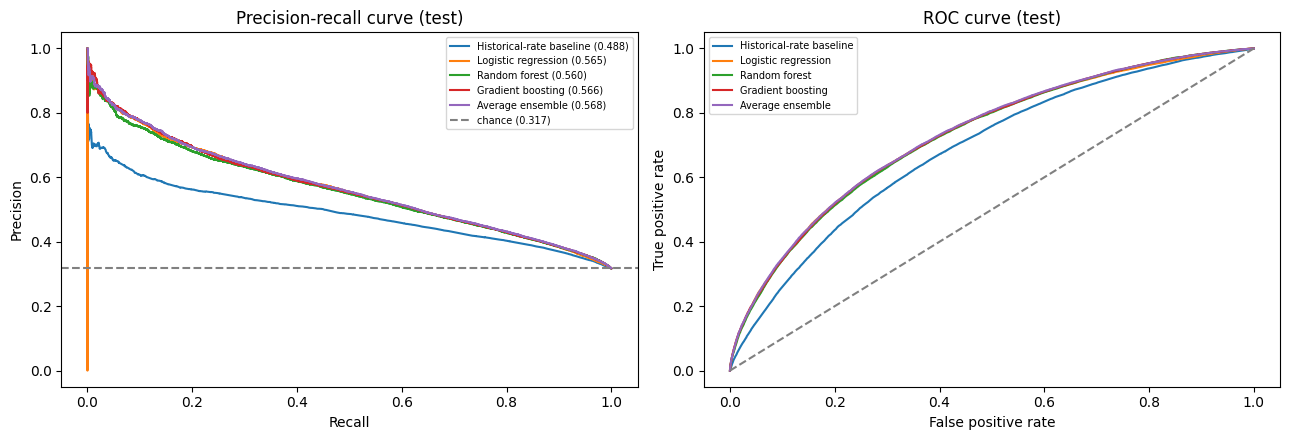

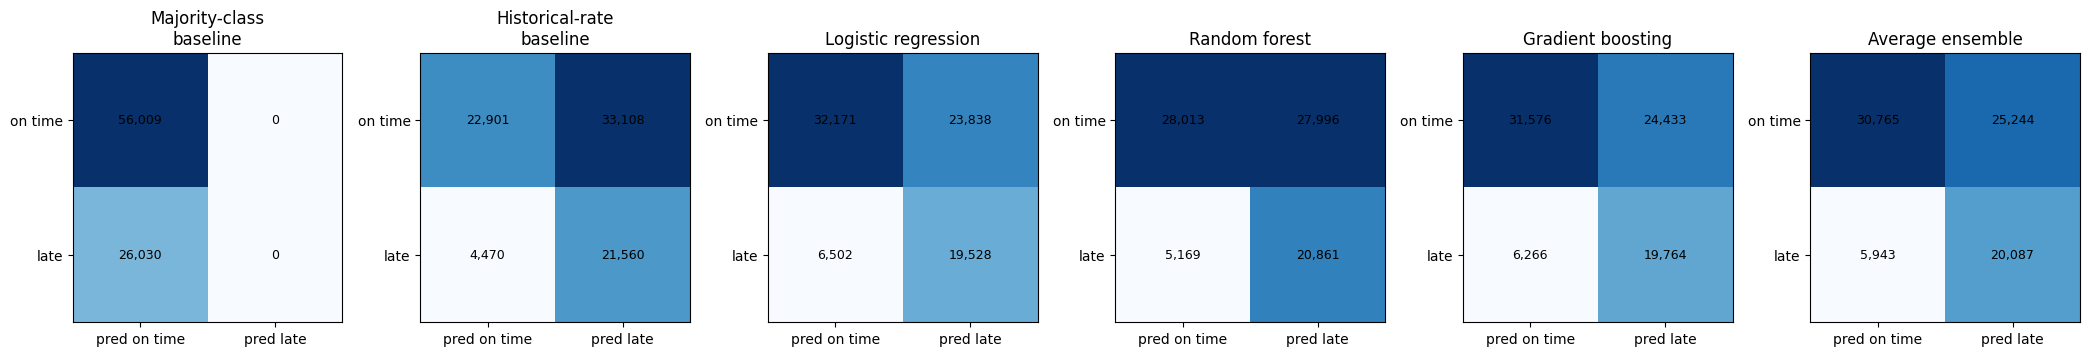

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for m in MODELS[1:]:
    p, r, _ = precision_recall_curve(y_test, scores_test[m])
    ax[0].plot(r, p, label=f"{m} ({average_precision_score(y_test, scores_test[m]):.3f})")
    fpr, tpr, _ = roc_curve(y_test, scores_test[m]); ax[1].plot(fpr, tpr, label=m)
ax[0].axhline(y_test.mean(), color="gray", ls="--", label=f"chance ({y_test.mean():.3f})")
ax[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test)"); ax[0].legend(fontsize=7)
ax[1].plot([0, 1], [0, 1], "--", color="gray"); ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 6, figsize=(21, 3.6))
for a_, m in zip(axes, MODELS):
    r = test_table.loc[m]; cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=float)
    a_.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a_.text(j, i, f"{int(cm[i, j]):,}", ha="center", va="center", fontsize=9)
    a_.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["pred on time", "pred late"], yticklabels=["on time", "late"], title=m.replace(" baseline", "\nbaseline"))
plt.tight_layout(); plt.show()

### Scores for each test month

The same validation-chosen thresholds are used. Months with more delays give a different precision and F1 even for the same model, so read these next to each month's delay rate.

In [18]:
def group_scores(mask, label):
    out = []
    for m in MODELS[1:]:
        s, y = scores_test[m][mask], y_test[mask]
        r = metrics_at(y, s, thresholds[m])
        out.append({"group": label, "model": m, "flights": int(mask.sum()), "delay_rate": round(y.mean(), 3), "precision": round(r["precision"], 3),
                    "recall": round(r["recall"], 3), "f1": round(r["f1"], 3), "pr_auc": round(r["pr_auc"], 3)})
    return out
rows = []
for mth in TEST_MONTHS:
    rows += group_scores((test["month"] == mth).values, MONTH_NAMES[mth - 1] + " 2024")
month_scores = pd.DataFrame(rows); print(month_scores.to_string(index=False))

   group                    model  flights  delay_rate  precision  recall    f1  pr_auc
Jun 2024 Historical-rate baseline    40686       0.293      0.367   0.825 0.508   0.449
Jun 2024      Logistic regression    40686       0.293      0.423   0.725 0.535   0.511
Jun 2024            Random forest    40686       0.293      0.399   0.784 0.529   0.504
Jun 2024        Gradient boosting    40686       0.293      0.417   0.743 0.534   0.511
Jun 2024         Average ensemble    40686       0.293      0.415   0.752 0.535   0.513
Jul 2024 Historical-rate baseline    41353       0.341      0.421   0.831 0.559   0.523
Jul 2024      Logistic regression    41353       0.341      0.474   0.772 0.588   0.605
Jul 2024            Random forest    41353       0.341      0.452   0.816 0.582   0.601
Jul 2024        Gradient boosting    41353       0.341      0.476   0.773 0.589   0.607
Jul 2024         Average ensemble    41353       0.341      0.469   0.788 0.588   0.608


### Information only: what if the threshold had been tuned on the test months?

This is **not** a valid score (the test labels would be used to pick the threshold). It shows how much of the gap between validation and test comes from the threshold, because the delay rate changes between May and the test months.

In [19]:
rows = []
for m in FITTED:
    ora = metrics_at(y_test, scores_test[m], best_f1_threshold(y_test, scores_test[m]))
    rows.append({"model": m, "valid test F1 (threshold from validation)": round(float(test_table.loc[m, "f1"]), 3),
                 "oracle F1 (threshold tuned on test)": round(ora["f1"], 3), "oracle precision": round(ora["precision"], 3), "oracle recall": round(ora["recall"], 3)})
print(pd.DataFrame(rows).to_string(index=False))

              model  valid test F1 (threshold from validation)  oracle F1 (threshold tuned on test)  oracle precision  oracle recall
Logistic regression                                      0.563                                0.563             0.461          0.724
      Random forest                                      0.557                                0.562             0.459          0.725
  Gradient boosting                                      0.563                                0.564             0.455          0.740
   Average ensemble                                      0.563                                0.565             0.456          0.743


### Bootstrap: are the gains over the historical-rate baseline larger than noise?

In [20]:
rng = np.random.RandomState(RANDOM_STATE); nt = len(y_test)
def f1_fixed(y, s, thr):
    return f1_score(y, (s >= thr).astype(int), zero_division=0)
bp = {m: [] for m in MODELS[1:]}; bf = {m: [] for m in MODELS[1:]}
for _ in range(N_BOOT):
    i = rng.randint(0, nt, nt)
    for m in MODELS[1:]:
        bp[m].append(average_precision_score(y_test[i], scores_test[m][i])); bf[m].append(f1_fixed(y_test[i], scores_test[m][i], thresholds[m]))
rows = []
for m in FITTED:
    gp = np.array(bp[m]) - np.array(bp["Historical-rate baseline"]); gf = np.array(bf[m]) - np.array(bf["Historical-rate baseline"])
    lp, hp = np.percentile(gp, [2.5, 97.5]); lf, hf = np.percentile(gf, [2.5, 97.5])
    rows.append({"model": m, "PR-AUC gain": round(gp.mean(), 4), "PR-AUC 95% interval": f"[{lp:.4f}, {hp:.4f}]", "F1 gain": round(gf.mean(), 4),
                 "F1 95% interval": f"[{lf:.4f}, {hf:.4f}]", "larger than noise?": "yes" if lp > 0 and lf > 0 else "no"})
boot_table = pd.DataFrame(rows); print(boot_table.to_string(index=False))

              model  PR-AUC gain PR-AUC 95% interval  F1 gain  F1 95% interval larger than noise?
Logistic regression       0.0776    [0.0729, 0.0817]   0.0283 [0.0254, 0.0313]                yes
      Random forest       0.0720    [0.0677, 0.0761]   0.0227 [0.0201, 0.0251]                yes
  Gradient boosting       0.0783    [0.0738, 0.0827]   0.0285 [0.0253, 0.0313]                yes
   Average ensemble       0.0799    [0.0756, 0.0843]   0.0285 [0.0255, 0.0310]                yes


## 14. Ablation: what does each feature group add?
Same gradient-boosting settings every time, only the feature set changes.

In [21]:
abl_rows = []
if RUN_ABLATION:
    t0 = time.time(); cfg = best_hgb[1]
    for name, (cat_, num_) in FEATURE_SETS.items():
        prep = make_preprocessor(False, cat_, num_).fit(train[cat_ + num_])
        h = HistGradientBoostingClassifier(max_iter=HGB_MAX_ITER, class_weight="balanced", random_state=RANDOM_STATE, **cfg).fit(prep.transform(train[cat_ + num_]), y_train)
        sv = h.predict_proba(prep.transform(val[cat_ + num_]))[:, 1]; st_ = h.predict_proba(prep.transform(test[cat_ + num_]))[:, 1]
        thr = best_f1_threshold(y_val, sv); mv, mt_ = metrics_at(y_val, sv, thr), metrics_at(y_test, st_, thr)
        abl_rows.append({"feature set": name, "features": len(cat_) + len(num_), "val F1": round(mv["f1"], 3), "test precision": round(mt_["precision"], 3),
                         "test recall": round(mt_["recall"], 3), "test F1": round(mt_["f1"], 3), "test PR-AUC": round(mt_["pr_auc"], 3), "test ROC-AUC": round(mt_["roc_auc"], 3)})
        print(f"  {name} done ({time.time()-t0:.0f}s)")
    print(); print(pd.DataFrame(abl_rows).to_string(index=False))

  A. base (weather, schedule, 30-day rates) done (149s)
  B. + extra trailing rates done (318s)
  C. + airport status (full) done (489s)

                              feature set  features  val F1  test precision  test recall  test F1  test PR-AUC  test ROC-AUC
A. base (weather, schedule, 30-day rates)        29   0.544           0.406        0.828    0.545        0.523         0.709
                B. + extra trailing rates        34   0.549           0.428        0.789    0.555        0.538         0.719
               C. + airport status (full)        40   0.557           0.447        0.759    0.563        0.566         0.731


### What the models use

best single model on validation PR-AUC: Gradient boosting


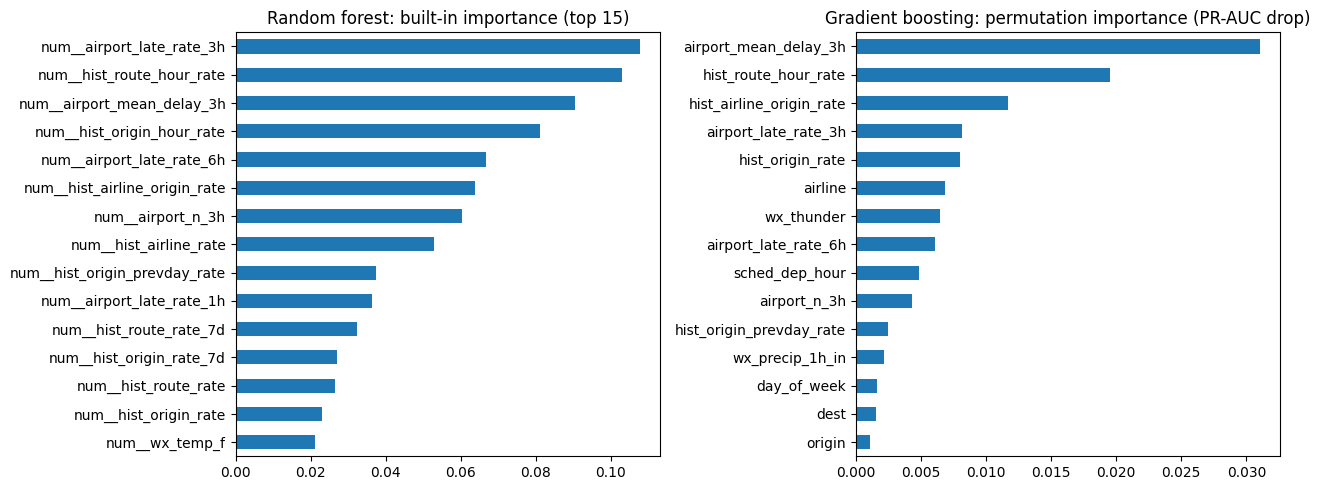

In [22]:
names = prep_rf.get_feature_names_out()
imp = pd.Series(rf_final.feature_importances_, index=names).sort_values(ascending=False).head(15)
best_name = max(FITTED[:3], key=lambda m: average_precision_score(y_val, scores_val[m]))
best_pipe = {"Logistic regression": lr_pipe, "Random forest": rf_pipe, "Gradient boosting": hgb_pipe}[best_name]
print("best single model on validation PR-AUC:", best_name)
smp = val.sample(min(10000, len(val)), random_state=RANDOM_STATE)
pi = permutation_importance(best_pipe, smp[FEATURES], smp["dep_del15"], scoring="average_precision", n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
perm = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
imp[::-1].plot.barh(ax=ax[0]); ax[0].set_title("Random forest: built-in importance (top 15)")
perm[::-1].plot.barh(ax=ax[1]); ax[1].set_title(f"{best_name}: permutation importance (PR-AUC drop)")
plt.tight_layout(); plt.show()

## 15. Final scorecard and files

In [23]:
final = test_table[show + ["tn", "fp", "fn", "tp"]].copy()
final[show] = final[show].astype(float).round(3); final[["tn", "fp", "fn", "tp"]] = final[["tn", "fp", "fn", "tp"]].astype(int)
print("=" * 90)
print(f"FINAL SCORECARD - departure delay (15+ min), 2 h before departure | train Jan 2023-Apr 2024 | validation {VAL_LABEL} | TEST {TEST_LABEL}")
print("=" * 90)
print(final.to_string())
best_test = test_table.loc[FITTED, "f1"].astype(float).idxmax()
print(f"\nBest F1 on the test set: {best_test} ({float(test_table.loc[best_test, 'f1']):.3f})")
print(f"Delayed flights in the test set: {int(y_test.sum()):,} of {len(y_test):,} ({y_test.mean():.1%}); validation: {y_val.mean():.1%}; train: {y_train.mean():.1%}")
print(); print(boot_table.to_string(index=False))
if abl_rows:
    print(); print("ABLATION (gradient boosting, test set)"); print(pd.DataFrame(abl_rows).to_string(index=False))
print(); print("PER TEST MONTH"); print(month_scores.to_string(index=False))

OUT_DIR = Path("results_2023_2024"); OUT_DIR.mkdir(exist_ok=True)
final.to_csv(OUT_DIR / "scores_test.csv"); val_table[show + ["tn", "fp", "fn", "tp"]].to_csv(OUT_DIR / "scores_validation.csv")
month_scores.to_csv(OUT_DIR / "scores_by_test_month.csv", index=False)
if abl_rows: pd.DataFrame(abl_rows).to_csv(OUT_DIR / "ablation.csv", index=False)
grid_t = np.round(np.arange(0, 1.0001, 0.01), 2)
web = {"task": "departure delay (15+ min), prediction 2 hours before scheduled departure",
       "train": "2023-01 to 2024-04", "validation": VAL_LABEL, "test_period": TEST_LABEL,
       "n_test": int(len(y_test)), "delay_rate_test": float(y_test.mean()), "models": {}}
for m in MODELS[1:]:
    s = scores_test[m]; rows = []
    for th in grid_t:
        pred = s >= th
        tp = int((pred & (y_test == 1)).sum()); fp = int((pred & (y_test == 0)).sum()); fn = int((~pred & (y_test == 1)).sum()); tn = int((~pred & (y_test == 0)).sum())
        pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
        rows.append({"threshold": float(th), "tp": tp, "fp": fp, "fn": fn, "tn": tn, "precision": pr, "recall": rc, "f1": 2 * pr * rc / (pr + rc) if pr + rc else 0.0})
    p, r, _ = precision_recall_curve(y_test, s); keep = np.linspace(0, len(p) - 1, min(200, len(p))).astype(int)
    web["models"][m] = {"chosen_threshold": thresholds[m], "pr_auc": float(average_precision_score(y_test, s)), "roc_auc": float(roc_auc_score(y_test, s)),
                        "by_threshold": rows, "pr_curve": {"precision": p[keep].round(4).tolist(), "recall": r[keep].round(4).tolist()}}
web["feature_importance"] = {"random_forest_builtin": imp.round(5).to_dict(), "permutation_best_model": perm.round(5).to_dict(), "best_model": best_name}
web["bootstrap_gain_vs_historical_baseline"] = boot_table.to_dict(orient="records"); web["ablation"] = abl_rows
with open(OUT_DIR / "results_for_website_2023_2024.json", "w") as f:
    json.dump(web, f)
print("\nsaved to", OUT_DIR)

FINAL SCORECARD - departure delay (15+ min), 2 h before departure | train Jan 2023-Apr 2024 | validation May 2024 | TEST Jun+Jul 2024
                          threshold  accuracy  precision  recall     f1  roc_auc  pr_auc     tn     fp     fn     tp
Majority-class baseline       1.000     0.683      0.000   0.000  0.000    0.500   0.317  56009      0  26030      0
Historical-rate baseline      0.204     0.542      0.394   0.828  0.534    0.686   0.488  22901  33108   4470  21560
Logistic regression           0.530     0.630      0.450   0.750  0.563    0.730   0.565  32171  23838   6502  19528
Random forest                 0.494     0.596      0.427   0.801  0.557    0.728   0.560  28013  27996   5169  20861
Gradient boosting             0.526     0.626      0.447   0.759  0.563    0.731   0.566  31576  24433   6266  19764
Average ensemble              0.516     0.620      0.443   0.772  0.563    0.732   0.568  30765  25244   5943  20087

Best F1 on the test set: Average ensemble (0.5

## 16. Save to Google Drive

In [24]:
try:
    from google.colab import drive, files
    import shutil, joblib
    drive.mount("/content/drive")
    D = Path("/content/drive/MyDrive/flight_delay_2023_2024"); D.mkdir(parents=True, exist_ok=True)
    for f in OUT_DIR.iterdir():
        shutil.copy(f, D / f.name)
    m24.to_parquet(D / "flights_weather_2024_10airports.parquet", index=False)      # the merged 2024 file, reusable later
    joblib.dump({"Logistic regression": lr_pipe, "Gradient boosting": hgb_pipe, "thresholds": thresholds, "features": FEATURES}, D / "models.joblib", compress=3)
    print("saved to", D)
    files.download(str(OUT_DIR / "scores_test.csv")); files.download(str(OUT_DIR / "results_for_website_2023_2024.json"))
except ImportError:
    m24.to_parquet(OUT_DIR / "flights_weather_2024_10airports.parquet", index=False)
    print("Not running in Colab - files are in", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saved to /content/drive/MyDrive/flight_delay_2023_2024


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to read the results
- **The threshold comes from May only.** Delay rates change by month, so test precision and F1 can differ from validation even for a good model. The per-month table and the "information only" table show how much is due to the threshold and the delay rate.
- **F1 cannot be compared across months with different delay rates** without looking at the rate: flagging every flight already gives F1 = 2p/(1+p), where p is the delay rate.
- **The ablation table is the evidence** for what the airport-status and extra-rate features add. Report it even if the gain is small.
- **Not included:** aircraft-rotation (tail number) features, because the 2024 file has no `TAIL_NUM` / `ARR_DELAY`.
- Predictions are not explanations: do not claim that a feature causes delays.